In [8]:
import sys
import time
import warnings
sys.path.append('..')
warnings.filterwarnings('ignore')

from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, StackingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
import optuna
import shap

from src.features.transformers import CutOrdinalEncoder, DiamondFeatureGenerator

optuna.logging.set_verbosity(optuna.logging.WARNING)
Path('../reports/png').mkdir(parents=True, exist_ok=True)
Path('../models').mkdir(parents=True, exist_ok=True)

# Используем датасет с пропусками из первого этапа (без 10-кратных синтетических выбросов)
data_path = Path('../data/raw/diamonds_with_missing.csv')
if not data_path.exists():
    data_path = Path('../data/raw/diamonds.csv')

df = pd.read_csv(data_path)
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

X = df.drop(columns=['price'])
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

num_cols = ['carat', 'depth', 'table', 'x', 'y', 'z', 'cut']
cat_cols = ['color', 'clarity']

# Конвейер предобработки с учётом наработок предыдущего этапа
preprocessor = Pipeline([
    ('cut_enc', CutOrdinalEncoder(column_name='cut')),
    ('col_trans', ColumnTransformer([
        ('num', Pipeline([
            ('scaler', StandardScaler()),
            ('imputer', KNNImputer(n_neighbors=5))
        ]), num_cols),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), cat_cols)
    ])),
    ('feat_gen', DiamondFeatureGenerator())
])

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

# Получаем имена всех признаков после трансформации для интерпретации в SHAP
ohe_names = list(
    preprocessor.named_steps['col_trans']
    .named_transformers_['cat']
    .named_steps['ohe']
    .get_feature_names_out(cat_cols)
)
feature_names = num_cols + ohe_names + ['volume', 'carat_sq', 'depth_table_ratio']

X_train_df = pd.DataFrame(X_train_prep, columns=feature_names, index=X_train.index)
X_test_df = pd.DataFrame(X_test_prep, columns=feature_names, index=X_test.index)

print(f"Train shape после предобработки: {X_train_df.shape}")
print(f"Test shape после предобработки:  {X_test_df.shape}")

Train shape после предобработки: (43152, 25)
Test shape после предобработки:  (10788, 25)


In [9]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

boosting_models = {
    'XGBoost (Baseline)': XGBRegressor(random_state=42, n_jobs=-1),
    'LightGBM (Baseline)': LGBMRegressor(random_state=42, n_jobs=-1, verbose=-1),
    'CatBoost (Baseline)': CatBoostRegressor(random_state=42, verbose=0, thread_count=-1)
}

baseline_results = []

for name, model in boosting_models.items():
    start_time = time.time()
    cv_scores = cross_validate(
        model, X_train_df, y_train,
        cv=cv,
        scoring={
            'rmse': 'neg_root_mean_squared_error',
            'mae': 'neg_mean_absolute_error',
            'r2': 'r2'
        },
        n_jobs=-1
    )
    elapsed = time.time() - start_time
    
    mean_rmse = -cv_scores['test_rmse'].mean()
    std_rmse = cv_scores['test_rmse'].std()
    mean_mae = -cv_scores['test_mae'].mean()
    mean_r2 = cv_scores['test_r2'].mean()
    
    baseline_results.append({
        'Модель': name,
        'CV RMSE (mean)': round(mean_rmse, 2),
        'CV RMSE (std)': round(std_rmse, 2),
        'CV MAE': round(mean_mae, 2),
        'CV R^2': round(mean_r2, 4),
        'Время (сек)': round(elapsed, 2)
    })
    print(f"{name:22s} | CV RMSE: {mean_rmse:.2f} ± {std_rmse:.2f} | MAE: {mean_mae:.2f} | R^2: {mean_r2:.4f} | Время: {elapsed:.2f} с")

baseline_df = pd.DataFrame(baseline_results)
baseline_df

XGBoost (Baseline)     | CV RMSE: 585.34 ± 12.59 | MAE: 293.77 | R^2: 0.9785 | Время: 13.82 с
LightGBM (Baseline)    | CV RMSE: 561.83 ± 11.14 | MAE: 292.98 | R^2: 0.9802 | Время: 16.61 с
CatBoost (Baseline)    | CV RMSE: 558.11 ± 11.84 | MAE: 284.86 | R^2: 0.9804 | Время: 34.21 с


,Модель,CV RMSE (mean),CV RMSE (std),CV MAE,CV R^2,Время (сек)
0,XGBoost (Baseline),585.34,12.59,293.77,0.9785,13.82
1,LightGBM (Baseline),561.83,11.14,292.98,0.9802,16.61
2,CatBoost (Baseline),558.11,11.84,284.86,0.9804,34.21


In [10]:
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 200, 1000, step=100),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.15, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 20, 120),
        'max_depth': trial.suggest_int('max_depth', 4, 15),
        'min_child_samples': trial.suggest_int('min_child_samples', 10, 100),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-4, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-4, 10.0, log=True),
        'random_state': 42,
        'n_jobs': -1,
        'verbose': -1
    }
    
    model = LGBMRegressor(**params)
    scores = cross_validate(
        model, X_train_df, y_train,
        cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1
    )
    return -scores['test_score'].mean()

sampler = optuna.samplers.TPESampler(seed=42)
study = optuna.create_study(direction='minimize', sampler=sampler)
study.optimize(objective, n_trials=50, show_progress_bar=True)

print(f"\nЛучший CV RMSE в Optuna: {study.best_value:.2f}")
print("Лучшие гиперпараметры:")
for k, v in study.best_params.items():
    print(f"  {k}: {v}")

Best trial: 0. Best value: 585.635:   2%|▏         | 1/50 [00:39<31:57, 39.13s/it]


[W 2026-11-17 01:15:30,102] Trial 1 failed with parameters: {'n_estimators': 800, 'learning_rate': 0.010573268083515799, 'num_leaves': 117, 'max_depth': 13, 'min_child_samples': 29, 'subsample': 0.6727299868828402, 'colsample_bytree': 0.6733618039413735, 'reg_alpha': 0.0033205591037519565, 'reg_lambda': 0.042051564509138675} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "c:\Users\user\Desktop\lab1_mlops\venv\Lib\site-packages\optuna\study\_optimize.py", line 210, in _run_trial
    value_or_values = func(trial)
  File "C:\Users\user\AppData\Local\Temp\ipykernel_18896\3893728985.py", line 18, in objective
    scores = cross_validate(
        model, X_train_df, y_train,
        cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1
    )
  File "c:\Users\user\Desktop\lab1_mlops\venv\Lib\site-packages\sklearn\utils\_param_validation.py", line 218, in wrapper
    return func(*args, **kwargs)
  File "c:\Users\user\Desktop\lab1_mlops\venv\Lib\

KeyboardInterrupt: 

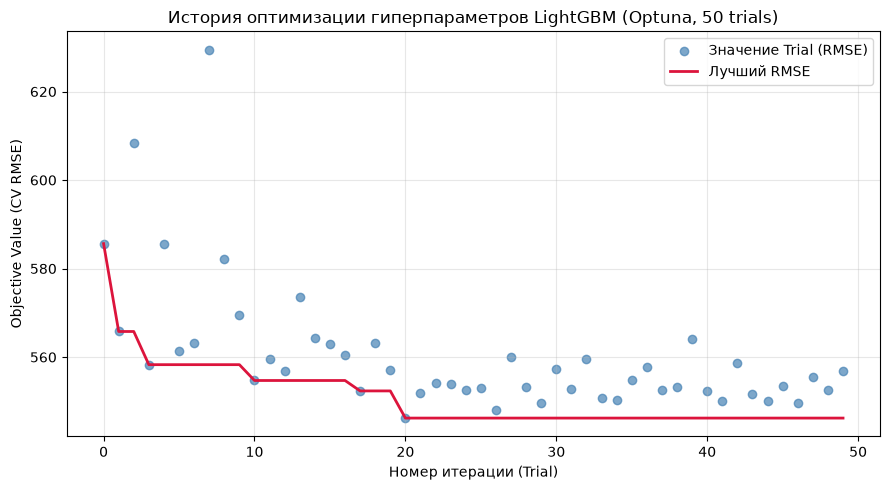

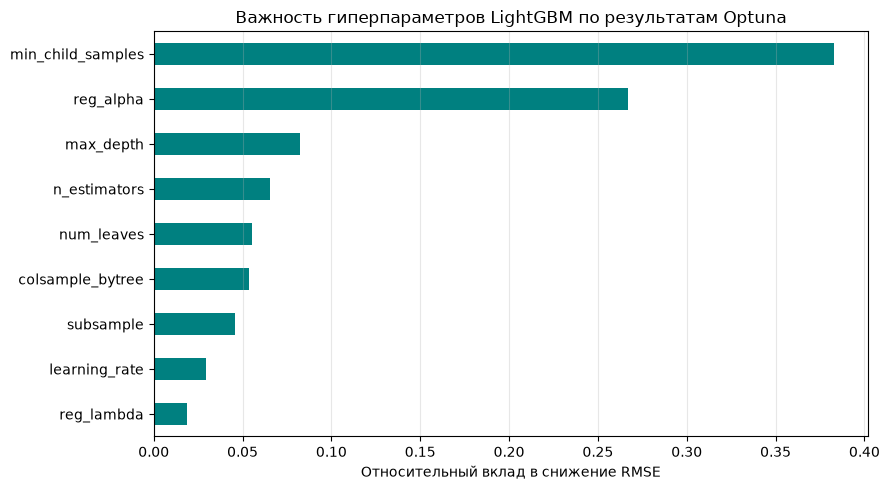

In [ ]:
# 1. График истории оптимизации
trials_df = study.trials_dataframe()
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(trials_df['number'], trials_df['value'], color='steelblue', alpha=0.7, label='Значение Trial (RMSE)')
ax.plot(trials_df['number'], trials_df['value'].cummin(), color='crimson', linewidth=2, label='Лучший RMSE')
ax.set_title('История оптимизации гиперпараметров LightGBM (Optuna, 50 trials)')
ax.set_xlabel('Номер итерации (Trial)')
ax.set_ylabel('Objective Value (CV RMSE)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../reports/png/optuna_history.png', dpi=150)
plt.show()

# 2. График важности гиперпараметров
importances = optuna.importance.get_param_importances(study)
imp_series = pd.Series(importances).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))
imp_series.plot(kind='barh', color='teal', ax=ax)
ax.set_title('Важность гиперпараметров LightGBM по результатам Optuna')
ax.set_xlabel('Относительный вклад в снижение RMSE')
ax.grid(alpha=0.3, axis='x')
plt.tight_layout()
plt.savefig('../reports/png/optuna_importance.png', dpi=150)
plt.show()

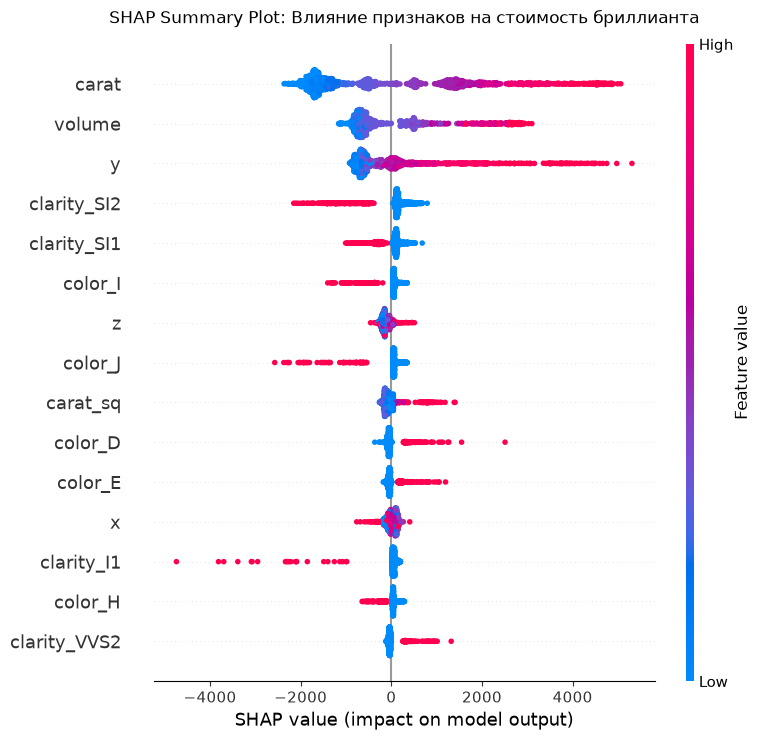

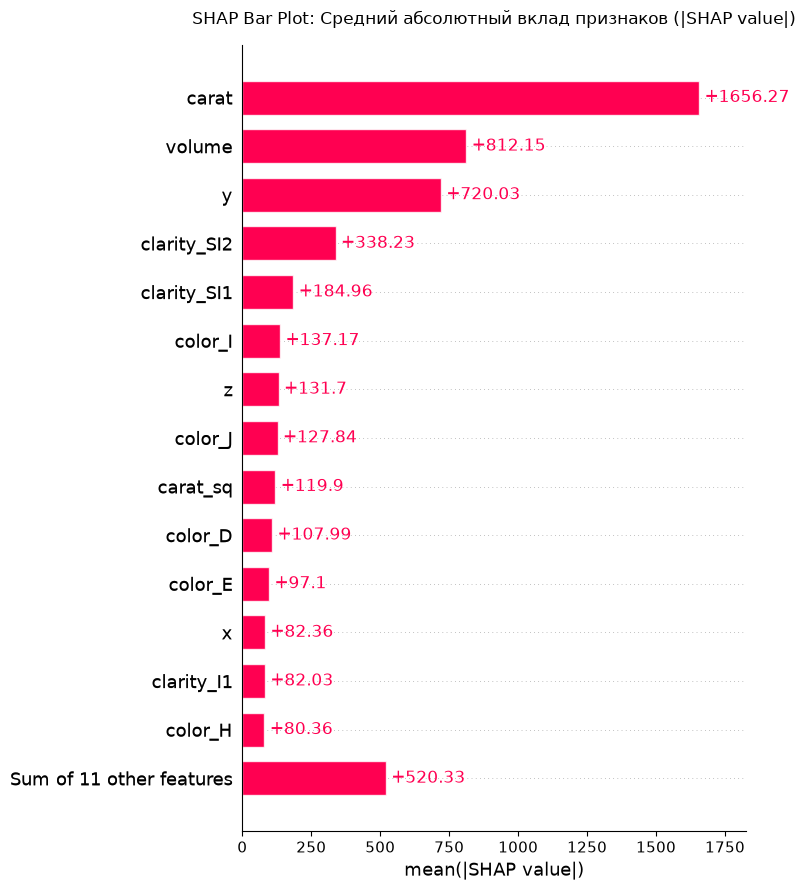

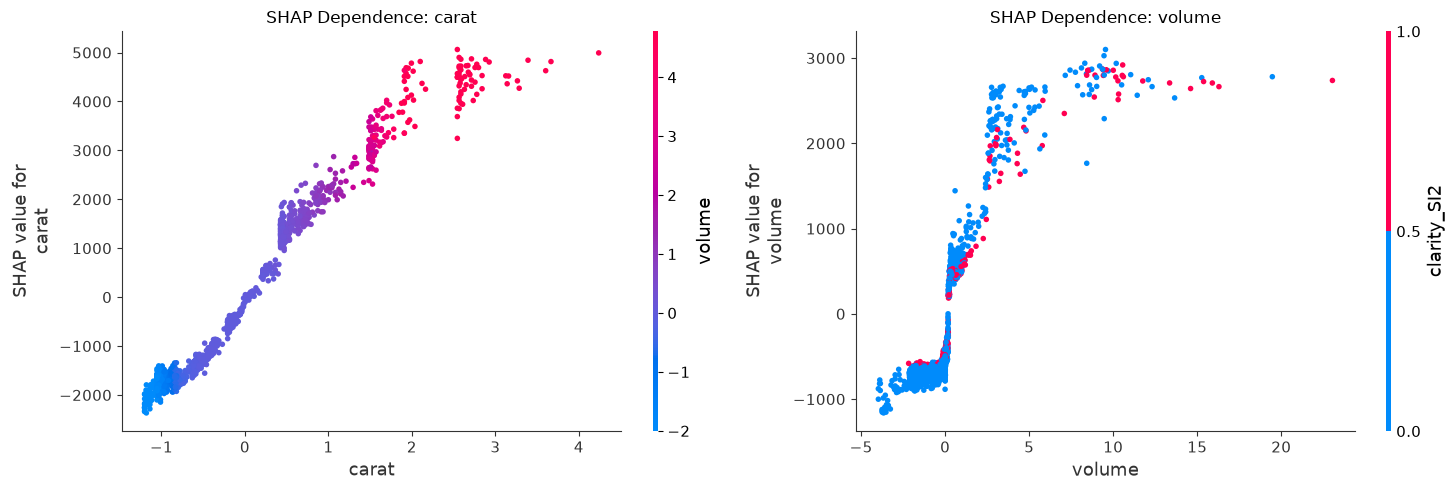

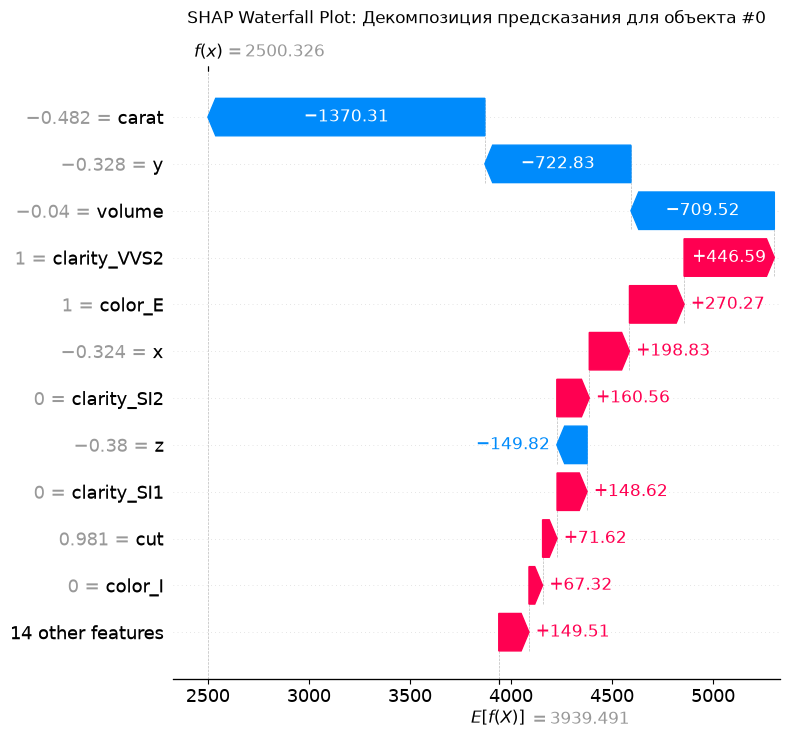

In [ ]:
best_lgbm_params = {**study.best_params, 'random_state': 42, 'n_jobs': -1, 'verbose': -1}
best_lgbm = LGBMRegressor(**best_lgbm_params)
best_lgbm.fit(X_train_df, y_train)

# Берём репрезентативную подвыборку из 1500 тестовых объектов для быстрого расчёта SHAP
X_shap = X_test_df.sample(n=1500, random_state=42)
explainer = shap.TreeExplainer(best_lgbm)
shap_values = explainer(X_shap)

# 1. SHAP Summary Plot (Beeswarm)
plt.figure(figsize=(10, 7))
shap.summary_plot(shap_values, X_shap, max_display=15, show=False)
plt.title('SHAP Summary Plot: Влияние признаков на стоимость бриллианта', pad=15)
plt.tight_layout()
plt.savefig('../reports/png/shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

# 2. SHAP Bar Plot (глобальная важность признаков)
plt.figure(figsize=(10, 6))
shap.plots.bar(shap_values, max_display=15, show=False)
plt.title('SHAP Bar Plot: Средний абсолютный вклад признаков (|SHAP value|)', pad=15)
plt.tight_layout()
plt.savefig('../reports/png/shap_bar.png', dpi=150, bbox_inches='tight')
plt.show()

# Определяем 2 самых важных признака автоматически
mean_abs_shap = np.abs(shap_values.values).mean(axis=0)
top2_idx = np.argsort(mean_abs_shap)[::-1][:2]
top1_feat, top2_feat = feature_names[top2_idx[0]], feature_names[top2_idx[1]]

# 3. SHAP Dependence Plots для двух самых важных признаков
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
shap.dependence_plot(top1_feat, shap_values.values, X_shap, ax=axes[0], show=False)
axes[0].set_title(f'SHAP Dependence: {top1_feat}')
shap.dependence_plot(top2_feat, shap_values.values, X_shap, ax=axes[1], show=False)
axes[1].set_title(f'SHAP Dependence: {top2_feat}')
plt.tight_layout()
plt.savefig('../reports/png/shap_dependence.png', dpi=150, bbox_inches='tight')
plt.show()

# 4. SHAP Waterfall Plot для отдельного объекта (объяснение локального предсказания)
plt.figure(figsize=(10, 6))
shap.plots.waterfall(shap_values[0], max_display=12, show=False)
plt.title('SHAP Waterfall Plot: Декомпозиция предсказания для объекта #0', pad=15)
plt.tight_layout()
plt.savefig('../reports/png/shap_waterfall.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# По варианту 9: Стекинг из LightGBM + RandomForest + ExtraTreesRegressor с cv=5
estimators = [
    ('lgbm', LGBMRegressor(**best_lgbm_params)),
    ('rf', RandomForestRegressor(n_estimators=100, max_depth=20, min_samples_split=5, random_state=42, n_jobs=-1)),
    ('et', ExtraTreesRegressor(n_estimators=100, max_depth=20, min_samples_split=5, random_state=42, n_jobs=-1))
]

stacking_model = StackingRegressor(
    estimators=estimators,
    final_estimator=RidgeCV(),
    cv=5,
    n_jobs=-1
)

print("Оценка StackingRegressor на кросс-валидации...")
stack_cv_scores = cross_validate(
    stacking_model, X_train_df, y_train,
    cv=cv,
    scoring={
        'rmse': 'neg_root_mean_squared_error',
        'mae': 'neg_mean_absolute_error',
        'r2': 'r2'
    },
    n_jobs=-1
)

stack_cv_rmse = -stack_cv_scores['test_rmse'].mean()
stack_cv_std = stack_cv_scores['test_rmse'].std()
print(f"Stacking CV RMSE: {stack_cv_rmse:.2f} ± {stack_cv_std:.2f}")

Оценка StackingRegressor на кросс-валидации...
Stacking CV RMSE: 534.08 ± 9.14


In [ ]:
# Обучаем все модели на полном X_train_df и сравниваем на отложенном X_test_df
final_models = {
    '1. XGBoost (Baseline)': XGBRegressor(random_state=42, n_jobs=-1),
    '2. LightGBM (Baseline)': LGBMRegressor(random_state=42, n_jobs=-1, verbose=-1),
    '3. CatBoost (Baseline)': CatBoostRegressor(random_state=42, verbose=0, thread_count=-1),
    '4. LightGBM (Optuna Tuned)': best_lgbm,
    '5. Stacking (LGBM + RF + ET)': stacking_model
}

test_comparison = []
fitted_models = {}

for name, model in final_models.items():
    t0 = time.time()
    model.fit(X_train_df, y_train)
    fit_time = time.time() - t0
    
    preds = model.predict(X_test_df)
    rmse = root_mean_squared_error(y_test, preds)
    mae = mean_absolute_error(y_test, preds)
    r2 = r2_score(y_test, preds)
    
    fitted_models[name] = model
    test_comparison.append({
        'Модель / Подход': name,
        'Test RMSE': round(rmse, 2),
        'Test MAE': round(mae, 2),
        'Test R^2': round(r2, 4),
        'Fit Time (s)': round(fit_time, 2)
    })

comparison_df = pd.DataFrame(test_comparison)
print("=== Сводная таблица качества на отложенной выборке (X_test) ===")
display(comparison_df)

# Выбираем лучшую модель по минимальному Test RMSE и упаковываем в единый Pipeline
best_row = comparison_df.loc[comparison_df['Test RMSE'].idxmin()]
best_model_name = best_row['Модель / Подход']
print(f"\nЛучшая модель на тесте: {best_model_name} (RMSE = {best_row['Test RMSE']:.2f})")

production_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', fitted_models[best_model_name])
])

joblib.dump(production_pipeline, '../models/pipeline_boosting.joblib', compress=3)
print("Финальный конвейер сохранён в ../models/pipeline_boosting.joblib")

=== Сводная таблица качества на отложенной выборке (X_test) ===


,Модель / Подход,Test RMSE,Test MAE,Test R^2,Fit Time (s)
0,1. XGBoost (Baseline),566.57,289.13,0.9798,0.47
1,2. LightGBM (Baseline),541.69,287.43,0.9815,0.28
2,3. CatBoost (Baseline),540.22,281.19,0.9816,7.03
3,4. LightGBM (Optuna Tuned),534.62,269.46,0.9820,1.01
4,5. Stacking (LGBM + RF + ET),521.09,257.15,0.9829,49.45



Лучшая модель на тесте: 5. Stacking (LGBM + RF + ET) (RMSE = 521.09)
Финальный конвейер сохранён в ../models/pipeline_boosting.joblib
